# Full beer-game experiment — performance, β, and H1/H2_API

1. **The selected stage is now the full game**, with 8 groups per cell and 36 weeks. The selected mode is API. Run All will send paid requests after the free measurement check. Set MODE = "offline" first for a free software run.
2. Every completed game produces **team cost, inventory, backlog, customer fulfillment, bullwhip, and weekly plots**, even when β cannot be estimated reliably.
3. **β results** show both the raw fit and a separately marked usable estimate. Unidentified β stays blank; it is not replaced with zero.
4. **H1:** training increases β. **H2_API:** low reasoning effort reduces β among trained agents. H2_API does not reproduce human 60/120-second time pressure.
5. Eight groups per cell meet the reporting floor only if all 8 blocks have reliable β. Eight is not a power calculation. No protocol can guarantee that free-choice GPT behavior identifies β or supports either hypothesis.

The first completed API game's results can be viewed below immediately, without another API call. The recent 64-request run was diagnostics only. Keep this notebook beside beer_game_v2.py. Your prior results remain separate.


In [1]:
# Uncomment only if dependencies are missing, then restart the kernel.
# %pip install "openai>=2,<3" "pydantic>=2.8,<3" numpy pandas scipy matplotlib ipykernel
from pathlib import Path
import sys, importlib, os, getpass

BASE = Path.cwd()
if (BASE / "Project" / "beer_game_experiment").is_dir():
    BASE = BASE / "Project" / "beer_game_experiment"
elif (BASE / "beer_game_experiment").is_dir():
    BASE = BASE / "beer_game_experiment"
if not (BASE / "beer_game_v2.py").exists():
    raise FileNotFoundError("Open this notebook in the beer_game_experiment folder, beside beer_game_v2.py.")
sys.path.insert(0, str(BASE))
import beer_game_v2 as study
importlib.reload(study)
from IPython.display import display, Markdown


In [2]:
# View the ORIGINAL completed API game now — this cell sends no requests.
import pandas as pd
original_run = BASE / "results" / "api_023f89662165ca64"
if (original_run / "performance.csv").exists():
    old_performance = pd.read_csv(original_run / "performance.csv")
    old_teams = old_performance.groupby(["group_id", "trained", "deadline_s"]).total_cost.sum().reset_index()
    display(Markdown("### Original API game: supply-chain cost (game units, not API dollars)"))
    display(old_teams.groupby(["trained", "deadline_s"]).total_cost.agg(["count", "mean", "median", "min", "max"]))
    old_beta = pd.read_csv(original_run / "agent_beta_fits.csv")
    old_beta["usable_beta"] = old_beta.beta.where(old_beta.usable)
    display(Markdown("### Original API game: β fits (blank = unidentified; timing exclusions are separate)"))
    display(old_beta[["agent_id", "alpha", "usable_beta", "usable", "primary_eligible", "fit_flag"]])
    print("Full prior tables:", original_run / "performance.csv", original_run / "agent_beta_fits.csv")


### Original API game: supply-chain cost (game units, not API dollars)

count     mean  median    min     max
trained deadline_s                                       
False   60              4  2749.75   836.0  156.0  9171.0
        120             4   696.75   156.0  156.0  2319.0
True    60              4   715.50   621.0  156.0  1464.0
        120             4   924.50   855.0  156.0  1832.0

### Original API game: β fits (blank = unidentified; timing exclusions are separate)

,agent_id,alpha,usable_beta,usable,primary_eligible,fit_flag
0,standard_120_00_distributor,0.071275,8.573538e-14,True,True,parameter_boundary
1,standard_120_00_factory,0.100906,4.078594e-11,True,True,parameter_boundary
2,standard_120_00_retailer,0.171446,3.145936e-11,True,True,parameter_boundary
3,standard_120_00_wholesaler,0.080580,4.760947e-12,True,True,parameter_boundary
4,standard_120_01_distributor,0.000007,NaN,False,False,weak_inventory_response;parameter_boundary
...,...,...,...,...,...,...
59,trained_60_02_wholesaler,0.000013,NaN,False,False,weak_inventory_response
60,trained_60_03_distributor,0.109845,5.749543e-09,True,True,parameter_boundary
61,trained_60_03_factory,0.106374,5.070579e-11,True,True,parameter_boundary
62,trained_60_03_retailer,0.000007,NaN,False,False,weak_inventory_response;parameter_boundary


Full prior tables: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/api_023f89662165ca64/performance.csv /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/api_023f89662165ca64/agent_beta_fits.csv


## 1. Full-game settings

The selected settings run **32 groups / 128 agents / 4,608 orders + 128 rules checks**. A $3 local allowance can stop before completion; it is not the projected cost or your account balance. Review the printed cost scenarios. Raise only BUDGET_USD to resume after a spending stop.

Use a fresh REPLICATE_ID for independent data. Successful cached responses are reused only for the same protocol. Changing the engine code or experimental settings creates a fresh run. Do not increase group count repeatedly while checking significance. Select a confirmation sample size after measuring estimation reliability and a meaningful effect size.


In [3]:
MODE = "offline"                 # "offline" or "api"
STAGE = "game"                   # Full four-role supply chain, not another diagnostic screen
GROUPS_PER_CELL = 8               # Reporting floor, NOT a power guarantee. Fix sample size before running.
WEEKS = 36
REPLICATE_ID = "offline-dashboard-verification"
SEED = 20260927
BUDGET_USD = 3.00                 # Local estimate guard for THIS run, not your account balance
MAX_OUTPUT_TOKENS = 8192          # Includes reasoning; same ceiling in all cells
REQUEST_TIMEOUT_S = 180           # Infrastructure timeout, NOT an experimental time treatment

CONFIG = dict(mode=MODE, stage=STAGE, model=study.MODEL,
    groups_per_cell=GROUPS_PER_CELL, weeks=WEEKS, replicate_id=REPLICATE_ID,
    seed=SEED, budget_usd=BUDGET_USD, max_output_tokens=MAX_OUTPUT_TOKENS,
    timeout_s=REQUEST_TIMEOUT_S)
requests_planned = 64 if STAGE == "diagnostics" else GROUPS_PER_CELL*16*(WEEKS+1)
print("Model:", study.MODEL)
print(f"{MODE.upper()} / {STAGE}: {requests_planned:,} planned requests; {BUDGET_USD:.2f} USD local allowance.")
print("FULL GAME selected" if STAGE == "game" else "DIAGNOSTICS ONLY: no game performance or beta")
print("Offline mode sends zero requests. API mode is paid.")
# Scenarios, not forecasts: cache discounts ignored. Game histories can be longer.
for output_tokens in (200, 1000, 3000):
    estimate = requests_planned*(2000*study.RATES['input']+output_tokens*study.RATES['output'])/1e6
    print(f"If average input=2,000 and total output={output_tokens:,} tokens/request: about ${estimate:.2f}.")


Model: gpt-5.4-mini-2026-03-17
OFFLINE / game: 4,736 planned requests; 3.00 USD local allowance.
FULL GAME selected
Offline mode sends zero requests. API mode is paid.
If average input=2,000 and total output=200 tokens/request: about $11.37.
If average input=2,000 and total output=1,000 tokens/request: about $28.42.
If average input=2,000 and total output=3,000 tokens/request: about $71.04.


## 2. What changed and what a “proper reply” means

- Same neutral game rules and structured response fields for all agents. Responses include an order and exact readbacks of the observed state. Copying demand is permitted; an order need not match our hypothesis to be valid.
- Trained agents get a supply-line lesson with worked examples and feedback. Controls get a similar-length record-keeping lesson. Neither sees H1, H2, β, or a desired effect.
- Four basic rules questions are checked in each role context. These standalone checks screen the prompt/model, not persistent human-like learning. They do not provide adaptive coaching or select only successful agents.
- A refusal, incomplete response, incorrect readback, or API failure stops the run and preserves the record. No fabricated orders, repeated sampling until correct, or automatic changes to token limits.
- `reasoning.effort` is low/high using the **same model**. Record reasoning tokens and latency to check the manipulation. The common timeout is only for infrastructure.
- Game demand varies across weeks to offer more information for β estimation. Its path is balanced across conditions and hidden from agents in advance. Diagnostic states are separate and never injected into the game.

[Official model capabilities/pricing](https://developers.openai.com/api/docs/models/gpt-5.4-mini) · [Reasoning controls](https://developers.openai.com/api/docs/guides/reasoning) · [Structured outputs](https://developers.openai.com/api/docs/guides/structured-outputs)

Inspect the exact materials below. After the pilot, freeze these before an independent confirmation run. Training examples are repeated in context each request; the API does not learn new model weights.

In [4]:
print("SHARED RULES\n", study.STANDARD)
print("\nCONTROL LESSON\n", study.CONTROL)
print("\nTRAINING LESSON\n", study.TRAINING)


SHARED RULES
 You manage one role in a four-role beer supply chain: retailer,
wholesaler, distributor, factory. Minimize total team holding and backlog costs
across repeated weeks. Holding costs 0.5 per unit per week; backlog costs 1.
Only your local state and your own past rounds are available. No communication
with other roles. Orders take one week upstream, shipping takes two weeks
downstream, and factory production takes three weeks. Capacity is unlimited.
Orders cannot be canceled. Inventory is available stock; backlog is unfilled
customer demand; net inventory = inventory - backlog. Supply line is everything
previously ordered but not yet received. The state is AFTER this week's receipts
and shipments, BEFORE your new order. Future demand and the final week are unknown.
Choose any nonnegative integer order to pursue the cost objective. There is no
required ordering strategy or target order. Return the requested structured fields.
The observed_* fields must copy the current observ

## 3. Run — the only cell that sends API requests

The progress bar counts completed responses, including rules checks, and shows how many remain. Requests run sequentially to limit budget exposure, but four game orders all use the same weekly snapshot before any are committed. Close or interrupt the cell to stop.

If the local spending guard stops, successful responses are cached; raising only `BUDGET_USD` allows resumption. If an actual request failed, preserve the failed pilot, fix the reported issue, and start a fresh replicate. Unknown failed-request usage is conservatively reserved. Changing settings is a new experiment, not a continuation of the old data.

In [5]:
# Free estimator check: known beta must be recovered; copied demand must be rejected.
measurement_checks = study.measurement_self_check()
display(measurement_checks)
if not measurement_checks.passed.all():
    raise RuntimeError("Estimator self-check failed. Stop before running paid requests.")
print("Software check passed. This does not guarantee that GPT behavior will identify beta.")


,case,true_beta,estimated_beta,usable,passed
0,known beta 0.0,0.00,4.744894e-07,True,True
1,known beta 0.3,0.30,3.000000e-01,True,True
2,known beta 0.65,0.65,6.500000e-01,True,True
3,known beta 1.0,1.00,1.000000e+00,True,True
4,copy demand: beta must be unidentified,NaN,NaN,False,True


Software check passed. This does not guarantee that GPT behavior will identify beta.


In [6]:
results, run_dir = None, None
client = None
try:
    if MODE == "api":
        from openai import AsyncOpenAI
        key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
        if not key.strip():
            raise ValueError("An API key is required in API mode.")
        client = AsyncOpenAI(api_key=key.strip(), max_retries=0, timeout=REQUEST_TIMEOUT_S)
        del key
    results, run_dir = await study.run_study(BASE, CONFIG, client=client)
    print("Saved to:", run_dir)
finally:
    if client is not None:
        await client.close()


Saved to: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/v2_offline_7c309ff7ba6df872


## 4. Conclusions and detailed outputs

**Diagnostics:** compare how orders change when supply line varies with inventory held fixed, and vice versa. These finite differences are sensitivity checks, not β estimates. Flat responses or extensive zero orders mean the structural β model may still be unsuitable. Do not choose prompts based on whether trained orders move in the desired direction.

**Game:** fit β only when identification checks pass. Preserve all fitted values and exclusion reasons. The report shows conclusions first; CSV files hold the details.

There are two planned comparisons: H1 averaged across effort, and H2_API low−high among trained groups. Analysis uses paired **blocks of four groups**, not individual weeks. Two-sided paired sign-randomization p-values assume exchangeability under the sharp null; Holm adjustment accounts for the two tests. No p-values are reported for offline data, fewer than 8 complete blocks, or after any planned block is lost to β nonidentification. This conservative rule prevents significance testing on a behavior-selected subset. The reporting floor of 8 is not a power justification.

The β model is unchanged from v1: forecast + α × (target − net inventory − β × supply line), clipped at zero. If α is near zero, β is not identifiable. Do not relax this check to get a p-value.

**Where to see the outputs:** the next cell displays condition performance and role-level β directly. All groups remain in performance summaries, including those without usable β. The run folder contains `condition_performance.csv`, `group_performance.csv`, `role_performance.csv`, `weekly_performance.csv`, `supply_chain_performance.png`, `agent_beta_fits.csv`, `group_beta.csv`, and `hypothesis_tests.csv`. β is not a performance score; higher β means greater estimated attention to outstanding orders, not necessarily lower cost.


# SYNTHETIC SOFTWARE CHECK: v2 results

## Conclusions

1. These are synthetic decisions, not GPT results. No hypothesis conclusion or API cost follows from them.
2. 32/32 groups have four usable beta estimates; 0/128 roles copied demand every week.
3. H1 tests the training effect. H2_API tests reasoning effort, not 60/120-second human time pressure.
- H1_training_average: withheld: offline, fewer than 8 complete blocks, or excluded/incomplete data; no significance conclusion.
- H2_API_low_minus_high_trained: withheld: offline, fewer than 8 complete blocks, or excluded/incomplete data; no significance conclusion.

## Supply-chain performance (all groups)

```
 trained effort  groups  mean_team_cost  median_team_cost  min_team_cost  max_team_cost  mean_backlog_cost  mean_customer_fulfillment
   False   high       8        1317.000           1327.50          789.0         1864.0            357.250                        1.0
   False    low       8        1341.125           1320.50          818.5         1905.0            375.000                        1.0
    True   high       8        1308.875           1397.00          757.5         1690.5            359.625                        1.0
    True    low       8        1283.125           1247.25          758.5         1915.5            327.875                        1.0
```
Cost is in game cost units, not API dollars. Team cost sums all four roles. Customer fulfillment is cumulative retailer shipments / cumulative customer demand; it includes late deliveries and is not an on-time service measure. Bullwhip is sample variance of role orders / variance of incoming demand; it is undefined when incoming demand has zero variance. No terminal inventory penalty is added.

## Beta measurement coverage

```
                roles  usable_beta
trained effort                    
False   high       32           32
        low        32           32
True    high       32           32
        low        32           32
```
See agent_beta_fits.csv: beta_for_interpretation is blank when beta is unreliable. The raw optimizer beta is retained for audit only. See group_beta.csv for analysis_beta. Missing beta means unidentified, not zero and not a failed hypothesis.

![Supply-chain performance](supply_chain_performance.png)

## Hypothesis results

```
                   hypothesis  estimate  complete_blocks  planned_blocks  p_two_sided  p_holm  ci95_low  ci95_high predicted_direction                                                                       status
          H1_training_average  0.001381                8               8          NaN     NaN       NaN        NaN            positive withheld: offline, fewer than 8 complete blocks, or excluded/incomplete data
H2_API_low_minus_high_trained -0.000414                8               8          NaN     NaN       NaN        NaN            negative withheld: offline, fewer than 8 complete blocks, or excluded/incomplete data
```

CIs are descriptive paired bootstrap 95% intervals, not multiplicity-adjusted. The two planned p-values are Holm-adjusted. No p-values are computed after excluding any planned block; identification failures depend on behavior and can bias selection. Eight blocks is a reporting floor, not a power calculation.

## Spending and interpretation

Recorded estimated charges/reservations: $0.0000. Not an invoice or account balance.
The original pilot remains separate. This redesigned protocol cannot confirm effects in humans. Do not repeatedly change prompts, exclusions, sample size, or models until p < .05. Use the pilot to fix measurement, then freeze a new protocol and collect independent confirmation data.

Detailed files:
agent_beta_fits.csv
condition_performance.csv
group_beta.csv
group_performance.csv
hypothesis_tests.csv
role_performance.csv
rounds.csv
rules_checks.csv
weekly_performance.csv


### Supply-chain performance — all groups

,trained,effort,groups,mean_team_cost,median_team_cost,min_team_cost,max_team_cost,mean_backlog_cost,mean_customer_fulfillment
0,False,high,8,1317.000,1327.50,789.0,1864.0,357.250,1.0
1,False,low,8,1341.125,1320.50,818.5,1905.0,375.000,1.0
2,True,high,8,1308.875,1397.00,757.5,1690.5,359.625,1.0
3,True,low,8,1283.125,1247.25,758.5,1915.5,327.875,1.0


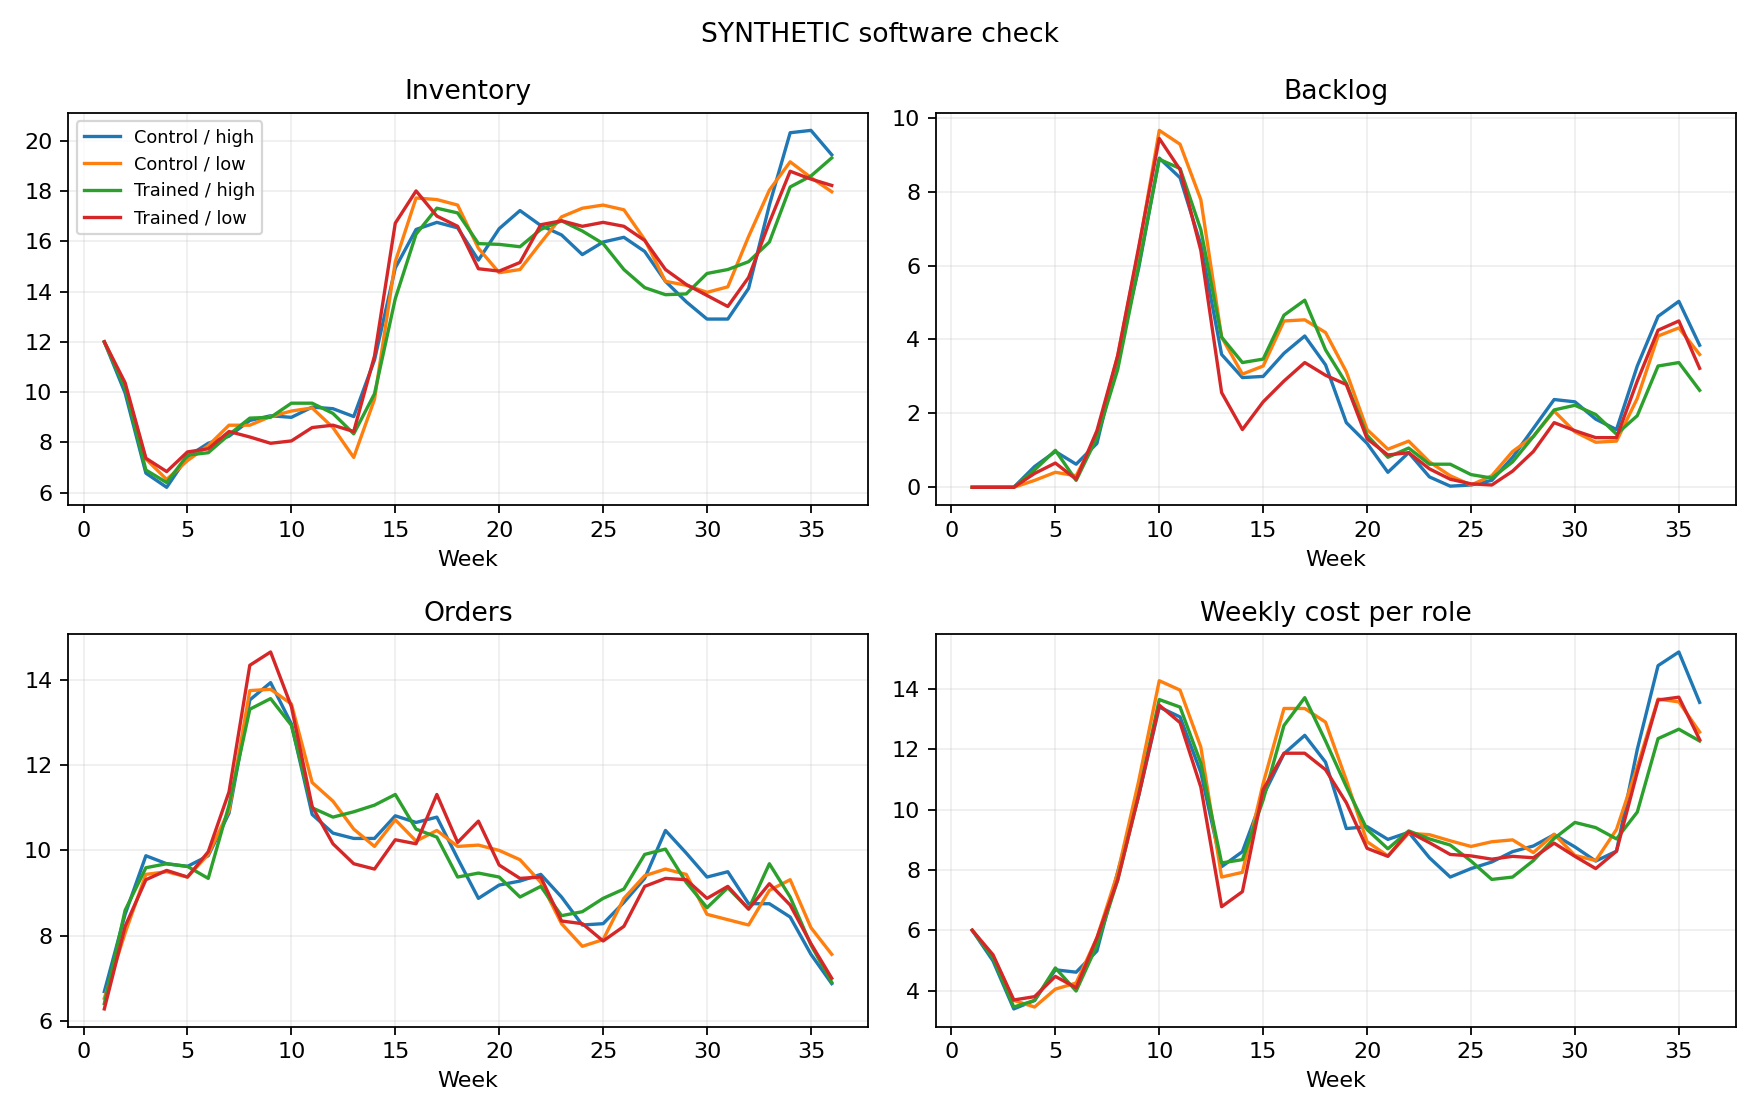

### Role-level β — blank means not identifiable

,agent_id,trained,effort,alpha,beta_for_interpretation,usable,fit_flag
0,b000_control_high_distributor,False,high,0.368642,0.602780,True,ok
1,b000_control_high_factory,False,high,0.317956,0.613751,True,ok
2,b000_control_high_retailer,False,high,0.410794,0.685335,True,ok
3,b000_control_high_wholesaler,False,high,0.357955,0.638901,True,ok
4,b000_control_low_distributor,False,low,0.378107,0.614062,True,ok
...,...,...,...,...,...,...,...
123,b007_trained_high_wholesaler,True,high,0.335883,0.633151,True,ok
124,b007_trained_low_distributor,True,low,0.364973,0.668913,True,ok
125,b007_trained_low_factory,True,low,0.359651,0.639394,True,ok
126,b007_trained_low_retailer,True,low,0.339099,0.675032,True,ok


### H1 / H2_API test status

,hypothesis,estimate,complete_blocks,planned_blocks,p_two_sided,p_holm,ci95_low,ci95_high,predicted_direction,status
0,H1_training_average,0.001381,8,8,NaN,NaN,NaN,NaN,positive,"withheld: offline, fewer than 8 complete block..."
1,H2_API_low_minus_high_trained,-0.000414,8,8,NaN,NaN,NaN,NaN,negative,"withheld: offline, fewer than 8 complete block..."


In [7]:
if results is None or run_dir is None:
    raise RuntimeError("Complete the run cell successfully before generating a report.")
report = study.make_report(results, run_dir, CONFIG)
display(Markdown(report))
print("Detailed files:")
for path in sorted(run_dir.glob("*.csv")):
    print(path.name)

if STAGE == "game":
    import pandas as pd
    from IPython.display import Image
    display(Markdown("### Supply-chain performance — all groups"))
    display(pd.read_csv(run_dir / "condition_performance.csv"))
    display(Image(filename=str(run_dir / "supply_chain_performance.png")))
    display(Markdown("### Role-level β — blank means not identifiable"))
    beta_results = pd.read_csv(run_dir / "agent_beta_fits.csv")
    display(beta_results[["agent_id", "trained", "effort", "alpha", "beta_for_interpretation", "usable", "fit_flag"]])
    display(Markdown("### H1 / H2_API test status"))
    display(pd.read_csv(run_dir / "hypothesis_tests.csv"))


## 5. Plan sample size before a confirmation run

Larger samples can improve power **after** reliable measurement is demonstrated. The table below uses a normal approximation for 80% power and conservative two-sided α=.025 per hypothesis. The standardized effect is a meaningful block contrast divided by its standard deviation, not a target picked to match this pilot. It ignores estimation failure and small-sample/randomization-test discreteness; use simulation-based planning with a stable pilot before treating a number as final.

Do not add groups repeatedly while checking p-values. Choose a fixed sample, analysis, prompts, model, and stopping rules beforehand. A significant result in this protocol would be evidence about these GPT agents under these conditions, not students.

In [8]:
display(study.sample_size_scenarios())


,standardized_paired_effect,approximate_groups_per_cell,total_groups,agents
0,0.3,106,424,1696
1,0.5,39,156,624
2,0.8,15,60,240
3,1.0,10,40,160
